# 01 — Data acquisition, audit, and target construction

This notebook loads the City of Cape Town SAP C3 Notifications extract, audits the columns that are actually present, and builds the three-class target. It does not train a model.

The raw file is read from `data/raw/`. CSV, Excel (`.xlsx`), and parquet are accepted. Set `DATA_RAW_FILE` if more than one file is present. The feature-service copy used here is `data/raw/c3_notifications.parquet`, saved on 16 October 2026 because the portal CSV export was still generating. That file is gitignored.

Sensitive fields are not printed. Coordinates, the notification identifier, `ObjectId`, and `Notification_type` (which mixes identifiers with free text) are omitted from displayed rows.


## 1. Setup


In [1]:
from pathlib import Path
import sys

import matplotlib
import pandas as pd

matplotlib.use("Agg", force=False)

cwd = Path.cwd().resolve()
project_root = None
for candidate in [cwd, *cwd.parents]:
    if (candidate / "src" / "config.py").is_file():
        project_root = candidate
        break
if project_root is None:
    raise FileNotFoundError("Start JupyterLab from the project folder.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src import config
from src.data_loader import (
    build_analysis_dataset,
    data_dictionary,
    duplicate_report,
    load_raw_table,
    representative_rows,
    resolve_raw_file,
    save_analysis_dataset,
    write_audit_tables,
)
from src.preprocessing import parse_portal_datetime, select_model_features
from src.visualization import save_duration_histogram

config.set_random_seeds(config.RANDOM_SEED)
print("Project root:", project_root)
print("Provisional threshold (days):", config.FAST_SLOW_THRESHOLD_DAYS)
print("Observation window (days):", config.OBSERVATION_WINDOW_DAYS)
print("Source page:", config.SOURCE_PAGE_URL)


Project root: /workspace
Provisional threshold (days): 7
Observation window (days): 7
Source page: https://odp-cctegis.opendata.arcgis.com/datasets/90711027d33940b5a06e96ad8a8f7ede_0/explore


## 2. Load the raw extract

The loader does not rename columns and does not write back to the raw file.


In [2]:
raw_path = resolve_raw_file()
raw = load_raw_table(raw_path)
print("File:", raw_path.name)
print("Shape:", raw.shape)
print("Columns:")
for name in raw.columns:
    print(f"  {name}: {raw[name].dtype}")


File: c3_notifications.parquet
Shape: (5372466, 14)
Columns:
  Sub_Council: str
  Ward: str
  Suburb: str
  C3_Complaint_Type: str
  Work_Center: str
  Notification: int64
  Notification_type: str
  X_Y_Co_ordinate_1: float64
  X_Y_Co_ordinate_2: float64
  Created_On_Date: int64
  Changed_on: float64
  Completed_Date: float64
  Notifications_Created: float64
  ObjectId: int64


## 3. Representative rows and date range

The table below is the first rows in `ObjectId` order, not a random sample. Coordinate columns and identifier columns are hidden. Date fields are stored in the raw file as UTC epoch milliseconds. The display converts them to a Cape Town calendar date. A value of 1672524000000 is 2022-12-31 22:00 UTC, which is 2023-01-01 00:00 in Africa/Johannesburg. The service itself labels the time reference as UTC.


In [3]:
preview = representative_rows(raw, rows=5).copy()
for column in preview.columns:
    key = str(column).casefold().replace(" ", "_")
    if key in {"created_on_date", "completed_date", "changed_on"}:
        preview[column] = parse_portal_datetime(preview[column]).dt.date
preview


,Sub_Council,Ward,Suburb,C3_Complaint_Type,Work_Center,Created_On_Date,Changed_on,Completed_Date,Notifications_Created
0,0,000,GENERIC TOWN 0000,No Power,Electricity - FLR-Gugulethu-Contractor,2026-04-16,2026-04-16,2026-04-16,1.0
1,0,000,GENERIC TOWN 0000,No Power,Electricity - FLR-Gugulethu-Contractor,2026-04-23,2026-04-29,2026-04-29,1.0
2,0,000,GENERIC TOWN 0000,No Power,Electricity - FLR-M'Plain-Contractor,2026-04-07,2026-04-07,2026-04-07,1.0
3,0,000,GENERIC TOWN 0000,No Power,Electricity - FLR-Muizenberg-Contractor,2026-04-19,2026-04-20,2026-04-20,1.0
4,0,000,GENERIC TOWN 0000,No Power,Electricity - FLR-Muizenberg-Contractor,2026-04-22,2026-04-22,2026-04-22,1.0


In [4]:
created = parse_portal_datetime(raw["Created_On_Date"])
completed = parse_portal_datetime(raw["Completed_Date"])
changed = parse_portal_datetime(raw["Changed_on"])
print("Created On Date:", created.min().date(), "to", created.max().date())
print("Completed Date:", completed.min().date(), "to", completed.max().date())
print("Changed on:", changed.min().date(), "to", changed.max().date())
print("Missing Created On Date:", int(created.isna().sum()))
print("Missing Completed Date:", int(completed.isna().sum()))
print("Missing Changed on:", int(changed.isna().sum()))


Created On Date: 2023-01-01 to 2026-10-06
Completed Date: 2000-01-01 to 2026-11-06
Changed on: 2023-01-01 to 2026-11-06
Missing Created On Date: 0
Missing Completed Date: 785115
Missing Changed on: 116320


## 4. Data dictionary and missingness

Meanings are filled only for columns whose names match the published layer. Distinct counts come from this file.


In [5]:
dictionary = data_dictionary(raw)
dictionary


,column,pandas_dtype,meaning,missing_count,missing_percent,distinct_values,proposed_use
0,Sub_Council,str,Subcouncil recorded on the request.,348869,6.4936,47,"Candidate predictor. Coarse area, not a precis..."
1,Ward,str,Ward recorded on the request.,93565,1.7416,220,"Candidate predictor. Coarse area, not a precis..."
2,Suburb,str,Suburb recorded on the request.,52761,0.9821,44905,"Candidate predictor. Coarse area, not a precis..."
3,C3_Complaint_Type,str,Complaint or request category.,0,0.0000,1154,Candidate predictor if it is known when the re...
4,Work_Center,str,Work centre named on the request.,0,0.0000,2076,Uncertain predictor. Use only if the centre is...
5,Notification,int64,Service-request identifier.,0,0.0000,4425943,Identifier. Not a model input.
6,Notification_type,str,Mixed field. On the published layer many rows ...,22,0.0004,1630557,Not a model input. Do not print the free-text ...
7,X_Y_Co_ordinate_1,float64,First coordinate attribute.,1152483,21.4517,2276268,Precise location. Not a model input and not sh...
8,X_Y_Co_ordinate_2,float64,Second coordinate attribute.,1152443,21.4509,2277380,Precise location. Not a model input and not sh...
9,Created_On_Date,int64,Date the request was logged.,0,0.0000,1323,Known at logging. Used for the observation cut...


## 5. Duplicates

`ObjectId` is the feature-service row number, so a full-row duplicate check that includes it is expected to be zero even when the City fields repeat.

Rule used below: if every business column is identical and only `ObjectId` differs, keep the first copy and drop the rest. Those rows would double-count one request. Rows that share a notification id but differ in another column are kept, because this phase does not decide which copy is the later update.


In [6]:
duplicates = duplicate_report(raw)
for key, value in duplicates.items():
    print(f"{key}: {value}")


exact_duplicate_rows_including_objectid: 0
exact_business_duplicate_rows: 779663
notification_ids_with_repeats: 709092
rows_in_repeated_notification_ids: 1655615


## 6. Target rule

Resolution duration is the Cape Town calendar-day difference Completed Date minus Created On Date.

The provisional threshold is **7 calendar days**. A completed request at or below 7 days is Resolved Fast. A longer completed request is Resolved Slow. This was not fitted to a model.

It is also not a citywide resolution standard:

- The City's corporate call centre standard aims to acknowledge written enquiries immediately and respond within 7 days. About 60% of enquiries are resolved at first contact, and the rest follow back-office standards. That 7 days is a response aim, not a resolution time for every service request. Source: City of Cape Town Schedule of Service Delivery Standards, Budget 2026/27 Annexure 18, Corporate Call Centre section.
- The Water and Sanitation customer charter uses 29 working days as the resolve standard for several water services. That applies to one directorate and to working days, not to every C3 notification.
- A 2016 News24 report of the then mayoral committee member for utility services says there is no average turnaround time because it depends on the department.

Open requests are Unresolved only when they are at least 7 days old at the observation cutoff. Younger open requests are left unlabelled (`insufficient_follow_up`). They are not counted as failures.

The cutoff is the latest parsed Created On Date in the file. Requests logged near that date have had less time to be completed. A completion dated after the cutoff is treated as not yet known at the cutoff, then the same open-request rule is applied.

Completed durations longer than 365 days are flagged `unusual_long` and kept. A long duration can be a real job. It is not deleted.


In [7]:
analysis, report = build_analysis_dataset(raw)
print("Rows in raw file:", report["raw_rows"])
print("Rows after the duplicate rule:", report["rows_after_duplicate_rule"])
print("Observation cutoff:", report["reference_date"])
print("Created On Date range:", report["created_min"], "to", report["created_max"])
print("Completed Date range:", report["completed_min"], "to", report["completed_max"])
print("Completions dated before 2023-01-01:", report["completed_before_2023"])
print("Completions dated after the cutoff:", report["completed_after_reference"])
print("Changed on before Created On Date:", report["changed_before_created"])
print("Malformed Changed on:", report["malformed_changed_on"])
print("Exclusion counts:")
for reason, rows in sorted(report["exclusion_counts"].items()):
    print(f"  {reason}: {rows}")
print("Target counts:")
for outcome, rows in sorted(report["target_counts"].items(), key=lambda item: str(item[0])):
    print(f"  {outcome}: {rows}")


Rows in raw file: 5372466
Rows after the duplicate rule: 4592803
Observation cutoff: 2026-10-06
Created On Date range: 2023-01-01 to 2026-10-06
Completed Date range: 2000-01-01 to 2026-11-06
Completions dated before 2023-01-01: 20
Completions dated after the cutoff: 3080
Changed on before Created On Date: 0
Malformed Changed on: 0
Exclusion counts:
  completion_before_creation: 20
  insufficient_follow_up: 15981
  labelled: 4576802
Target counts:
  None: 16001
  Resolved Fast: 2969242
  Resolved Slow: 937145
  Unresolved: 670415


## 7. Duration distribution

Quantiles are for completed requests that received a Fast or Slow label. The histogram draws durations up to 90 days only. Longer durations remain in the table and in the file.


Completed and labelled: 3906387
At or below 7 days: 2969242
Share at or below 7 days: 0.7601
p50: 2.0 days
p75: 7.0 days
p90: 32.0 days
p99: 236.0 days
Retained durations over 365 days: 14953


Saved evidence/reproducibility/notebooks/isolated/results/figures/01_resolution_duration.png


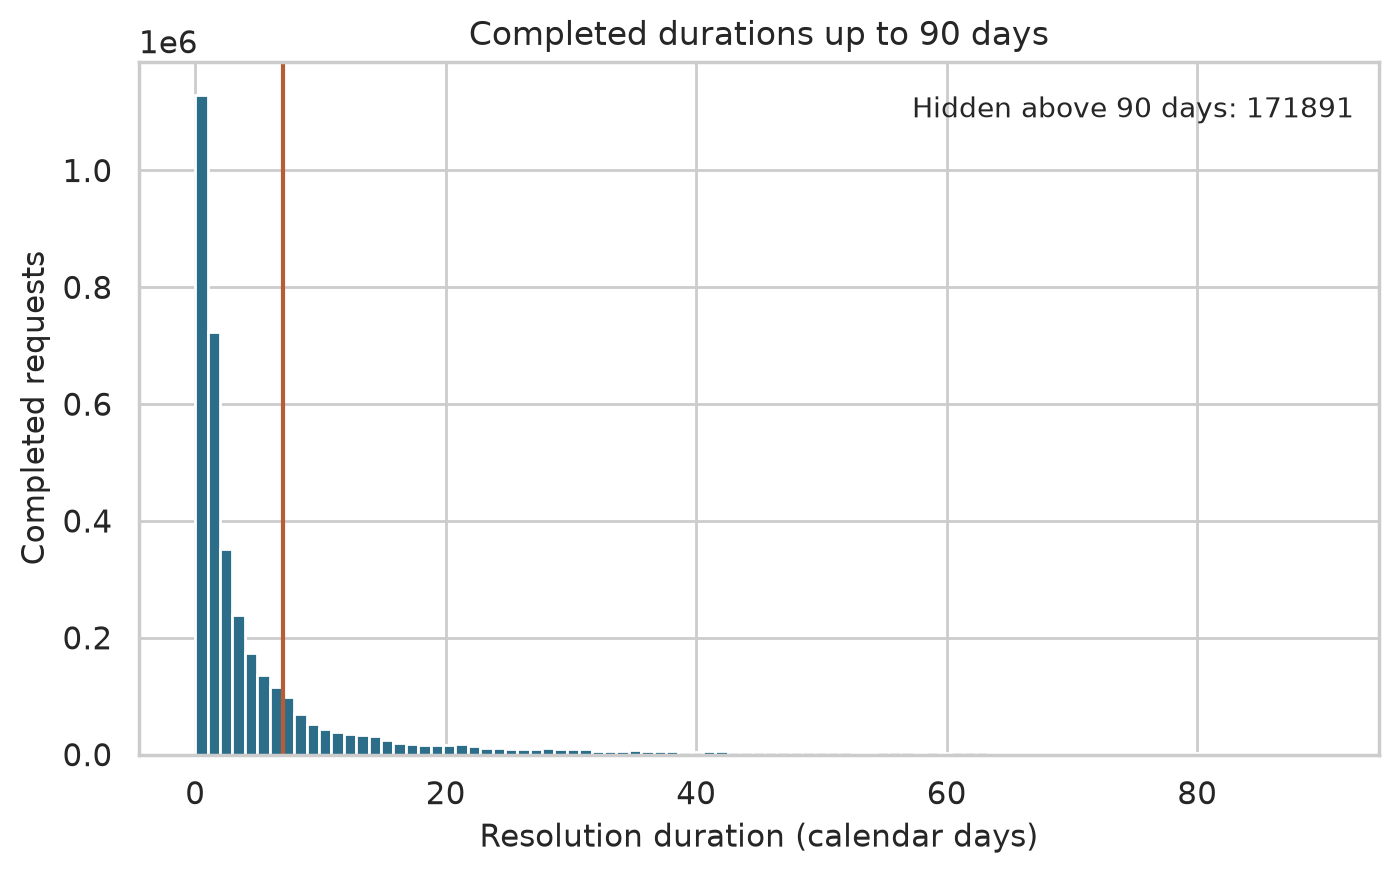

In [8]:
quantiles = report["duration_quantiles_days"]
completed_n = report["completed_duration_count"]
within = report["completed_within_threshold"]
print("Completed and labelled:", completed_n)
print("At or below 7 days:", within)
if completed_n:
    print("Share at or below 7 days:", round(within / completed_n, 4))
for name, value in quantiles.items():
    print(f"{name}: {value} days")
print("Retained durations over 365 days:", report["unusual_long_durations_retained"])
from IPython.display import Image, display
figure, figure_path = save_duration_histogram(analysis["resolution_days"], report["threshold_days"])
print("Saved", figure_path.relative_to(config.PROJECT_ROOT))
display(Image(filename=str(figure_path)))


## 8. Personal information, location, and the notification fields

The published columns do not include a name, phone number, email address, or street address. The precise-location fields are the two coordinate attributes. They are not shown and they are not model inputs.

On the published layer, only a handful of coordinate pairs fall in a Cape Town longitude/latitude box. Many more fall in a local metre envelope (coordinate 1 between -200000 and 200000, coordinate 2 between 3600000 and 4000000). Pairs outside that envelope are flagged and kept. The envelope is not an official EPSG code.

`Notification` is an identifier. `Notification_type` equals that identifier on a large share of rows and holds other text on the rest. The text is not printed. The column is removed from the analysis file. `Notifications Created` has very few distinct values, so it carries little information. It is not used to build the label.


In [9]:
print("Coordinate flags on the analysis rows:")
for status, rows in sorted(report["coordinate_quality_counts"].items()):
    print(f"  {status}: {rows}")
print("Notification type equal to the notification id:", report["notification_type_matches_id"])
print("Notification type not equal to that id:", report["notification_type_other"])
print("Suburb value '#':", int((raw["Suburb"] == "#").sum()))
print("Suburb value 'GENERIC TOWN 0000':", int((raw["Suburb"] == "GENERIC TOWN 0000").sum()))
print("Distinct Suburb values:", int(dictionary.loc[dictionary["column"] == "Suburb", "distinct_values"].iloc[0]))
print("Distinct Work_Center values:", int(dictionary.loc[dictionary["column"] == "Work_Center", "distinct_values"].iloc[0]))
print(raw["Notifications_Created"].value_counts(dropna=False).rename("rows").to_frame())


Coordinate flags on the analysis rows:
  missing: 1035640
  outside_local_grid: 2515158
  plausible_local_grid: 1042005
Notification type equal to the notification id: 1222465
Notification type not equal to that id: 3370338
Suburb value '#': 428314
Suburb value 'GENERIC TOWN 0000': 4720
Distinct Suburb values: 44905
Distinct Work_Center values: 2076
                          rows
Notifications_Created         
1.0                    5351778
2.0                      16997
NaN                       3588
3.0                        103


## 9. Save the analysis table

Completed Date, Changed on, the coordinate values, and Notification type are not in this file. Resolution duration and the label are stored so the audit can be checked, and `select_model_features` removes them from the default feature list.


In [10]:
import json
saved_path = save_analysis_dataset(analysis)
tables = write_audit_tables(dictionary, report)
print("Analysis file:", saved_path)
print("Analysis shape:", analysis.shape)
print("Default model features:")
for name in select_model_features(analysis.columns):
    print(" ", name)
print("Blocked examples still present in the file but not in the feature list:")
for name in ["resolution_days", "resolution_outcome", "label_status", "Notification", "ObjectId"]:
    if name in analysis.columns:
        print(" ", name, "-> blocked")
for path in tables.values():
    print("Table:", path.relative_to(config.PROJECT_ROOT))

report_path = config.TABLES_DIR / "02_audit_report.json"
report_path.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
print("Report:", report_path.relative_to(config.PROJECT_ROOT))


Analysis file: /workspace/evidence/reproducibility/notebooks/isolated/processed/service_requests_labelled.parquet
Analysis shape: (4592803, 16)
Default model features:
  Sub_Council
  Ward
  Suburb
  C3_Complaint_Type
  Work_Center
  Created_On_Date
  Notifications_Created
Blocked examples still present in the file but not in the feature list:
  resolution_days -> blocked
  resolution_outcome -> blocked
  label_status -> blocked
  Notification -> blocked
  ObjectId -> blocked
Table: evidence/reproducibility/notebooks/isolated/results/tables/02_data_dictionary.csv
Table: evidence/reproducibility/notebooks/isolated/results/tables/02_missingness.csv
Table: evidence/reproducibility/notebooks/isolated/results/tables/02_target_distribution.csv
Table: evidence/reproducibility/notebooks/isolated/results/tables/02_exclusion_counts.csv
Table: evidence/reproducibility/notebooks/isolated/results/tables/02_cleaning_decisions.csv
Table: evidence/reproducibility/notebooks/isolated/results/tables/02_d

## 10. Feasibility

The last cell writes the measured summary. It does not train a model.


In [11]:
labelled_rows = report["exclusion_counts"].get("labelled", 0)
fast = report["target_counts"].get("Resolved Fast", 0)
slow = report["target_counts"].get("Resolved Slow", 0)
unresolved = report["target_counts"].get("Unresolved", 0)
lines = [
    "# Phase 2 feasibility",
    "",
    f"The raw extract has {report['raw_rows']} rows and {raw.shape[1]} columns.",
    f"Created On Date runs from {report['created_min']} to {report['created_max']}.",
    f"The observation cutoff is {report['reference_date']}, the latest created date in the file.",
    f"Exact business duplicates removed: {report['exact_business_duplicate_rows_removed']}.",
    f"Before the duplicate rule, {duplicates['notification_ids_with_repeats']} notification ids repeat across {duplicates['rows_in_repeated_notification_ids']} rows.",
    f"After exact copies are removed, {report['notification_ids_with_repeats']} ids still repeat across {report['rows_in_repeated_notification_ids']} rows. Those rows are kept.",
    f"Rows after that rule: {report['rows_after_duplicate_rule']}.",
    f"Labelled rows: {labelled_rows}.",
    f"Resolved Fast: {fast}.",
    f"Resolved Slow: {slow}.",
    f"Unresolved: {unresolved}.",
    f"Excluded for completion before creation: {report['exclusion_counts'].get('completion_before_creation', 0)}.",
    f"Excluded for insufficient observation time: {report['exclusion_counts'].get('insufficient_follow_up', 0)}.",
    f"Excluded for malformed or missing created dates: {report['exclusion_counts'].get('malformed_created_date', 0) + report['exclusion_counts'].get('missing_created_date', 0)}.",
    f"Excluded for malformed completed dates: {report['exclusion_counts'].get('malformed_completed_date', 0)}.",
    f"Completed durations over 365 days retained: {report['unusual_long_durations_retained']}.",
    f"Median completed duration: {report['duration_quantiles_days'].get('p50')} days.",
    f"75th percentile of completed duration: {report['duration_quantiles_days'].get('p75')} days.",
    "",
    "The extract can support a three-class model. Resolved Fast is the largest labelled class. Resolved Slow and Unresolved both have hundreds of thousands of rows.",
    "",
    "Limitations:",
    "- The published layer is deprecated and was not connected to the live system. An open request may have been completed after the extract was taken.",
    "- The project plan ends on 18 September 2026. Created dates in this file continue through 6 October 2026.",
    "- Seven days is provisional. It matches the 75th percentile of completed durations in this file, but it is not a citywide resolution standard.",
    "- Completions dated after the cutoff are not treated as completed. Some completion dates also fall in the year 2000.",
    "- Coordinates are often missing or outside the local metre envelope, and they are withheld from the analysis file.",
    "- Notification type is not a clean category and is withheld.",
    "- Suburb has tens of thousands of distinct values. The most common stored value is the placeholder '#', and the first ObjectId rows use GENERIC TOWN 0000. It needs grouping before modelling.",
    "- Work centre may be assigned after logging. It is left in the feature list with that warning.",
    "- No model was trained in this notebook.",
]
summary = "\n".join(lines)
print(summary)
out_path = config.REPORTS_DIR / "phase2_feasibility.md"
out_path.write_text(summary + "\n", encoding="utf-8")
print("Wrote", out_path.relative_to(config.PROJECT_ROOT))


# Phase 2 feasibility

The raw extract has 5372466 rows and 14 columns.
Created On Date runs from 2023-01-01 to 2026-10-06.
The observation cutoff is 2026-10-06, the latest created date in the file.
Exact business duplicates removed: 779663.
Before the duplicate rule, 709092 notification ids repeat across 1655615 rows.
After exact copies are removed, 142898 ids still repeat across 309758 rows. Those rows are kept.
Rows after that rule: 4592803.
Labelled rows: 4576802.
Resolved Fast: 2969242.
Resolved Slow: 937145.
Unresolved: 670415.
Excluded for completion before creation: 20.
Excluded for insufficient observation time: 15981.
Excluded for malformed or missing created dates: 0.
Excluded for malformed completed dates: 0.
Completed durations over 365 days retained: 14953.
Median completed duration: 2.0 days.
75th percentile of completed duration: 7.0 days.

The extract can support a three-class model. Resolved Fast is the largest labelled class. Resolved Slow and Unresolved both have hu